# 10 · Simulating fights: a Markov-chain model

**The idea:** our models so far look at two fighters' numbers and output a probability.
This notebook instead *simulates* the fight, 5 seconds at a time, thousands of times. It is a simplified version of the most credible published UFC model:

> Holmes, McHale & Zychaluk (2023), *A Markov chain model for forecasting results of mixed martial arts contests*, International Journal of Forecasting 39(2).
> The authors report predictions "comparable to the bookmakers", which made money when used for betting.

**How a simulated fight works:**
- **The fight is always in one of four positions:** distance, clinch, fighter A on top, or fighter B on top.
- **Each 5-second step:**
  - Both fighters may land significant strikes, at *their* rate for that position against *this* opponent.
  - Every landed strike has a small chance of a knockdown and of ending the fight (KO/TKO).
  - On the ground, either fighter may attempt a submission, and an attempt may finish the fight.
  - The position may change: takedowns, clinch entries and breaks, stand-ups, reversals.
- **Rounds restart at distance.** A fight that survives every round goes to a **judge model** fitted on real decisions.
- **Rates are "A's offense × B's defense"** compared with the division average, from fights *before* the bout. They are shrunk toward the division average, so a debutant is an exactly average member of the division.

Because it plays the fight out, it answers more than "who wins": how, in which round, with what stat line. It can also show one fight play by play.
That makes it the engine for the fight simulator.

**This is a "Markov chain"** because the next step depends only on the current position, not on how the fight got there. That is a simplification: real fighters tire, and they adjust between rounds.

**Same rules as always:** settings are chosen on **2021–23 validation**. The **2024+ test** is scored once, against the current app model (63.8% · 0.634 log loss · AUC 0.696).

In [1]:
import os, sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

from ufc import markov as MK, modeling as M, form as F
from ufc.features import MIN_FEATURES, HIST_FEATURES
from ufc.predict import add_location, LOCATION_COLS
from ufc.viz import use_style, SERIES, INK_2, NEUTRAL, GRID, RED_CORNER, BLUE_CORNER, METHOD_COLORS
from sklearn.metrics import log_loss
use_style()

fights = pd.read_parquet("data/processed/fights.parquet")
ff = pd.read_parquet("data/processed/fighter_fights.parquet")
origin = pd.read_parquet("data/processed/fighter_origin.parquet")
VAL = pd.Timestamp("2021-01-01")
decided = fights[fights.corners_reliable & fights.winner.isin(["Red", "Blue"])]
va_f = decided[(decided.date >= VAL) & (decided.date < M.SPLIT)]
te_f = decided[decided.date >= M.SPLIT]
print(f"validation fights {len(va_f):,} · test fights {len(te_f):,} · data through {fights.date.max():%Y-%m-%d}")

validation fights 1,507 · test fights 1,475 · data through 2026-10-17


## 1 · Turning box scores into positions
ufcstats records *what* happened, but not *how long* the fight spent in each position. We estimate it per fight:
- **Control time** (either fighter) is split between **ground** and **clinch**, in proportion to where strike attempts and takedowns happened.
- **Ground time** is split between the fighters by their own control time. That gives "time on top" and "time on bottom".
- **Everything else** is distance.

The simulator uses exactly the same accounting. So "strikes per minute at distance" means the same thing in the data and in the simulation.

In [2]:
S0 = MK.Simulator(ff, VAL)
ex = S0.ex.join(S0.ff[["fight_id", "fighter", "opponent", "date", "result", "method_group"]])
example = ex[(ex.fighter == "Khabib Nurmagomedov") & (ex.opponent == "Conor McGregor")]
cols = ["t_dist", "t_clinch", "t_top", "t_bot", "o_dist_land", "o_clinch_land", "o_ground_land", "o_td", "a_dist_land", "a_clinch_land", "a_ground_land"]
print("Khabib vs McGregor (UFC 229): estimated minutes in each position and strikes landed (o_ = Khabib, a_ = McGregor)")
display(example[cols].round(1))
L = S0.L
print("Division averages from fights before 2021 (rates per minute in that position; ko / kd per landed strike)")
display(L.loc[["Flyweight", "Lightweight", "Middleweight", "Heavyweight", "Women's Strawweight", "ALL"],
              ["dist", "clinch", "gtop", "td", "sub", "subconv", "ko", "kd", "topdur", "share_dist", "share_clinch", "share_ground"]].round(4))

Khabib vs McGregor (UFC 229): estimated minutes in each position and strikes landed (o_ = Khabib, a_ = McGregor)


,t_dist,t_clinch,t_top,t_bot,o_dist_land,o_clinch_land,o_ground_land,o_td,a_dist_land,a_clinch_land,a_ground_land
9918,5.8,1.8,10.4,0.0,24.0,1.0,45.0,3.0,35.0,10.0,6.0


Division averages from fights before 2021 (rates per minute in that position; ko / kd per landed strike)


,dist,clinch,gtop,td,sub,subconv,ko,kd,topdur,share_dist,share_clinch,share_ground
Flyweight,3.6505,3.0517,3.4184,0.1793,0.1587,0.1911,0.0031,0.0066,0.9045,0.5838,0.1461,0.2702
Lightweight,4.0270,2.8164,3.3076,0.1515,0.1657,0.2367,0.0039,0.0065,1.1083,0.5737,0.1515,0.2747
Middleweight,3.4827,3.0660,3.7720,0.1353,0.1561,0.2604,0.0063,0.0100,1.1935,0.5633,0.1705,0.2662
Heavyweight,3.6377,3.4618,4.8293,0.1105,0.1102,0.3014,0.0093,0.0113,1.2884,0.5829,0.1787,0.2384
Women's Strawweight,4.9255,3.6120,4.3091,0.1010,0.1592,0.2649,0.0009,0.0013,1.0678,0.5971,0.2041,0.1988
ALL,4.0124,3.0626,3.7370,0.1381,0.1477,0.2415,0.0046,0.0074,1.1309,0.5760,0.1639,0.2601


**Reading the division table:**
- **Heavyweights:** each landed strike is more than twice as likely to end the fight (`ko`) as at lightweight. They also spend less time on the ground than most men's divisions.
- **Women's strawweight:** a landed strike is about a quarter as likely to end the fight as at lightweight. Of the divisions shown, these fights have the most clinch time and the least ground time.
- **Submission attempts** succeed about a quarter of the time (`subconv`), and more often at heavyweight.
- **A spell on top** lasts about a minute on average (`topdur`), a bit shorter at flyweight.
- **Small divisions use the overall averages.** Divisions with fewer than 300 fighter-fights before the cutoff (women's flyweight and bantamweight, catch weight) are given the all-division numbers.

## 2 · The judges
Fights that go the distance need a scorer. We fit a logistic regression on real decisions before 2021: who won, from the differences in significant strikes, knockdowns, takedowns, minutes on top, and submission attempts.
It's symmetric (no corner bias) and has no intercept.

In [3]:
J = S0.judge
print(f"fitted on {J.n:,} decisions · picks the official winner {J.acc:.1%} of the time")
coef = J.coef.rename("log-odds per unit").to_frame()
coef["unit"] = ["1 strike", "1 knockdown", "1 takedown", "1 minute on top", "1 attempt"]
coef["equal to this many strikes"] = (coef["log-odds per unit"] / coef.loc["sig_diff", "log-odds per unit"]).round(1)
display(coef.round(3))

fitted on 2,600 decisions · picks the official winner 85.3% of the time


,log-odds per unit,unit,equal to this many strikes
sig_diff,0.076,1 strike,1.0
kd_diff,0.622,1 knockdown,8.2
td_diff,0.172,1 takedown,2.3
top_diff,0.329,1 minute on top,4.3
subatt_diff,0.214,1 attempt,2.8


**What the judges reward:**
- One knockdown is worth about 8 significant strikes on the cards.
- A minute of top control is worth about 4.
- A takedown is worth about 2.

These are rough averages, because judges score round by round. Still, the model picks the official winner in about 85% of decisions using only box-score totals.

## 3 · Calibrating the simulator
A few league-wide settings aren't observed directly:
- how long ground spells last before a stand-up,
- how often fighters clinch,
- an overall scale on KO and submission hazards.

These are tuned so the simulated league matches the real one: time on the ground, time in the clinch, and the KO and submission rates.
The calibration uses a sample of 2015–20 fights, so it never touches validation or test. Strikes per minute and takedowns are **not** tuned. They are a free check of whether the per-fighter rates add up.

In [4]:
cal_f = decided[(decided.date >= "2015-01-01") & (decided.date < VAL)].sample(800, random_state=0)
BASE = dict(k_min=40.0, k_ko=150.0, k_sub=4.0)
S0.P = MK.Params(**BASE)
t0 = time.time()
tgt, got = MK.calibrate(S0, cal_f, n=300, iters=5)
print(f"calibrated in {time.time() - t0:.0f}s · multipliers: up {S0.P.up_mult:.2f} · clinch {S0.P.clinch_mult:.2f} · KO {S0.P.ko_mult:.2f} · SUB {S0.P.sub_mult:.2f}")
CAL = dict(up_mult=S0.P.up_mult, clinch_mult=S0.P.clinch_mult, ko_mult=S0.P.ko_mult, sub_mult=S0.P.sub_mult)

iter 0: ground 0.177/0.235  clinch 0.154/0.153  ko 0.328/0.347  sub 0.143/0.184


iter 1: ground 0.208/0.235  clinch 0.147/0.153  ko 0.324/0.347  sub 0.201/0.184


iter 2: ground 0.224/0.235  clinch 0.149/0.153  ko 0.339/0.347  sub 0.197/0.184


iter 3: ground 0.230/0.235  clinch 0.151/0.153  ko 0.346/0.347  sub 0.189/0.184


iter 4: ground 0.234/0.235  clinch 0.152/0.153  ko 0.349/0.347  sub 0.187/0.184
calibrated in 58s · multipliers: up 0.56 · clinch 1.08 · KO 1.17 · SUB 1.05


,real,simulated,tuned?
share of time on the ground,0.235,0.235,yes
share of time in the clinch,0.153,0.153,yes
KO/TKO rate,0.348,0.347,yes
submission rate,0.184,0.184,yes
decision rate,0.469,0.469,no
sig. strikes per minute (both),7.128,6.725,no
takedowns per 15 min (both),2.817,3.059,no
fight length (minutes),10.849,10.949,no


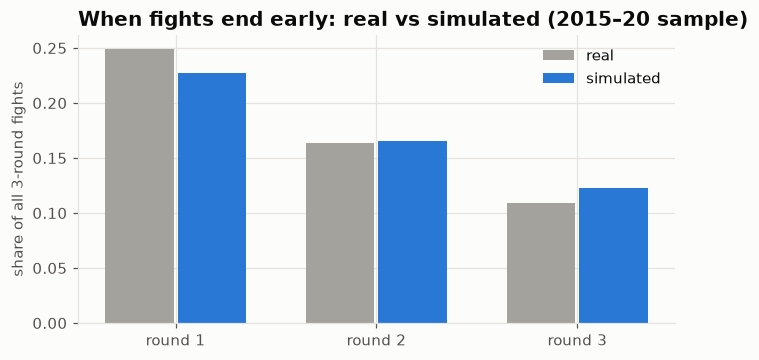

In [5]:
sim_cal = S0.run_fights(cal_f, n=400, seed=1)
m = S0.ff.fight_id.isin(cal_f.fight_id) & (S0.ff.corner == "Red")
e = S0.ex[m]
mins_real, mins_sim = e.t_total.sum(), sim_cal.mean_minutes.sum()
real_dec = (cal_f.method_group == "DEC").mean()
cmp_ = pd.DataFrame({
    "real": [e.t_ground.sum() / mins_real, e.t_clinch.sum() / mins_real, (cal_f.method_group == "KO/TKO").mean(), (cal_f.method_group == "SUB").mean(),
             real_dec, (e.o_sig_land.sum() + e.a_sig_land.sum()) / mins_real, 15 * (e.o_td.sum() + e.a_td.sum()) / mins_real,
             e.t_total.mean()],
    "simulated": [(sim_cal.mean_a_top + sim_cal.mean_b_top).sum() / mins_sim, sim_cal.mean_t_clinch.sum() / mins_sim,
                  (sim_cal["A KO/TKO"] + sim_cal["B KO/TKO"]).mean(), (sim_cal["A SUB"] + sim_cal["B SUB"]).mean(),
                  (sim_cal["A DEC"] + sim_cal["B DEC"]).mean(), (sim_cal.mean_a_sig + sim_cal.mean_b_sig).sum() / mins_sim,
                  15 * (sim_cal.mean_a_td + sim_cal.mean_b_td).sum() / mins_sim, sim_cal.mean_minutes.mean()],
    "tuned?": ["yes", "yes", "yes", "yes", "no", "no", "no", "no"]},
    index=["share of time on the ground", "share of time in the clinch", "KO/TKO rate", "submission rate", "decision rate",
           "sig. strikes per minute (both)", "takedowns per 15 min (both)", "fight length (minutes)"])
display(cmp_.round(3))

# finish-round distribution: real vs simulated (3-round fights)
three = cal_f.total_rounds == 3
pa, pb, cin = S0.fight_params(cal_f[three])
o = MK.simulate(pa, pb, cin, np.full(three.sum(), 3), S0.judge, S0.P, n=400, seed=2)
real_r = cal_f[three & (cal_f.method_group.isin(["KO/TKO", "SUB"]))].finish_round.value_counts(normalize=True).sort_index() * (cal_f[three].method_group.isin(["KO/TKO", "SUB"]).mean())
sim_r = pd.Series(o["finish_round"].mean(0), index=[1, 2, 3])
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(3)
ax.bar(x - 0.18, real_r.reindex([1, 2, 3]).values, 0.34, color=NEUTRAL, label="real")
ax.bar(x + 0.18, sim_r.values, 0.34, color=SERIES[0], label="simulated")
ax.set_xticks(x, ["round 1", "round 2", "round 3"]); ax.set_ylabel("share of all 3-round fights")
ax.set_title("When fights end early: real vs simulated (2015–20 sample)"); ax.legend(frameon=False)
plt.show()

**Reading the calibration check:**
- The four tuned shares match by design.
- The **untuned** numbers check whether the machinery holds together:
  - Fight length comes out almost exactly right.
  - Strikes per minute come out about 6% low, and takedowns about 8% high.
  - That's close for numbers built purely from per-fighter rates, but not perfect. The position-time estimates are rough.
- **Finish rounds:** the model knows nothing about fatigue or early chaos, so finishes are spread a little more evenly across rounds than in reality. Real fights end slightly more often in round 1 and less often in round 3.

## 4 · Choosing the settings on validation
Three choices:
- **Shrinkage:** how many minutes of "division-average fighting" to add to every career (`k_min`). For KO power and chin, the same idea is counted in landed strikes (`k_ko`).
- **Recency:** a `half_life` in years. With 2, a fight from 2 years ago counts half as much as one from last month, so rates follow a fighter's current form and decline.
- The calibration multipliers stay fixed from above.

Each setting is scored on 2021–23 fights (400 simulations per fight, same random numbers).

In [6]:
y_va = (va_f.winner == "Red").astype(int).values
L7 = sorted(M.OUTCOMES)
ll7 = lambda y, P: log_loss(y, P[L7].values, labels=L7)
out_va = np.where(va_f.method_group.isin(M.METHODS), va_f.winner + " " + va_f.method_group, "Other")
rows = []
t0 = time.time()
for hl in [None, 2, 4]:
    S = MK.Simulator(ff, VAL, half_life=hl)
    for km, kko in [(15, 150), (40, 150), (40, 400), (100, 400)]:
        S.P = MK.Params(k_min=km, k_ko=kko, k_sub=4.0, **CAL)
        s = S.run_fights(va_f, n=400, seed=0)
        p = s.p_a.clip(0.01, 0.99).values
        rows.append({"half_life (yrs)": hl or "none", "k_min": km, "k_ko": kko, **M.scores(y_va, p),
                     "7-outcome log loss": ll7(out_va, MK.outcome_probs(s))})
grid = pd.DataFrame(rows)
print(f"{len(grid)} settings in {time.time() - t0:.0f}s")
best = grid.loc[grid.log_loss.idxmin()]
print("chosen (lowest validation log loss):", best[["half_life (yrs)", "k_min", "k_ko"]].to_dict())
display(grid.round(4))

12 settings in 351s
chosen (lowest validation log loss): {'half_life (yrs)': 2, 'k_min': 40, 'k_ko': 400}


,half_life (yrs),k_min,k_ko,accuracy,log_loss,roc_auc,7-outcome log loss
0,none,15,150,0.5760,0.6918,0.6026,1.7961
1,none,40,150,0.5766,0.6819,0.5958,1.7270
2,none,40,400,0.5813,0.6767,0.5948,1.7037
3,none,100,400,0.5727,0.6786,0.5835,1.6873
4,2,15,150,0.5893,0.6783,0.6158,1.7631
5,2,40,150,0.5906,0.6744,0.6111,1.6957
6,2,40,400,0.5780,0.6700,0.6185,1.6997
7,2,100,400,0.5733,0.6759,0.6022,1.6942
8,4,15,150,0.5886,0.6798,0.6129,1.7488
9,4,40,150,0.5766,0.6750,0.6069,1.7258


**Reading the tuning grid:**
- **Recency weighting helps:** recent fights tell you more about a fighter than old ones.
- **Moderate shrinkage works best.** With too little, one wild fight dominates a short record. With too much, everyone looks average.
- All settings land between AUC 0.58 and 0.62. That ceiling comes from the inputs, not the tuning. See section 5.
- The best setting for *who wins* (log loss) isn't the best for *how* (7-outcome log loss), which prefers more shrinkage. We choose on who-wins log loss, as decided before running the grid.

## 5 · The test: 2024 onward
The chosen setting is rebuilt with everything before 2024: division averages, the judge model, and a recalibration on 2018–23 fights. It then simulates every test fight 1,000 times.

**The comparison models:**
- **Logistic on the same in-fight rates:** a logistic regression given only career strike and grappling rates. It isolates the value of *simulating* rather than *regressing*.
- **The current app model:** age, size, record, shrunk rates, "who they beat", and location. It also has the red-corner term, which captures UFC matchmaking.
  The Markov model is corner-neutral, so it can't use that.

In [7]:
HL = None if best["half_life (yrs)"] == "none" else float(best["half_life (yrs)"])
CHOSEN = dict(k_min=float(best.k_min), k_ko=float(best.k_ko), k_sub=4.0)

def build_sim(before, cal_from):
    S = MK.Simulator(ff, before, MK.Params(**CHOSEN), half_life=HL)
    cf = decided[(decided.date >= cal_from) & (decided.date < before)].sample(800, random_state=0)
    MK.calibrate(S, cf, n=300, iters=4, verbose=False)
    return S

t0 = time.time()
S21 = build_sim(VAL, "2015-01-01")
S24 = build_sim(M.SPLIT, "2018-01-01")
mk_va = S21.run_fights(va_f, n=1000, seed=0)
mk_te = S24.run_fights(te_f, n=1000, seed=0)
print(f"simulated {len(va_f) + len(te_f):,} fights × 1,000 in {time.time() - t0:.0f}s")

simulated 2,982 fights × 1,000 in 237s


In [8]:
# the logistic models on the same fights
t, _ = M.load_model_table(shrink_k=5)
t = add_location(t, ff, fights, origin)
FINAL = M.diffs(MIN_FEATURES + HIST_FEATURES) + M.FLAGS + ["red_corner"] + M.diffs(F.OPP_FEATURES) + LOCATION_COLS
RATES = M.diffs(M.RATE_FEATURES)
tr, va, trall, te = t[t.date < VAL], t[(t.date >= VAL) & (t.date < M.SPLIT)], t[t.date < M.SPLIT], t[t.date >= M.SPLIT]
te = te[te.fight_id.isin(te_f.fight_id)]
va = va[va.fight_id.isin(va_f.fight_id)]
mk_te_t = mk_te.set_index(te_f.fight_id).reindex(te.fight_id)
mk_va_t = mk_va.set_index(va_f.fight_id).reindex(va.fight_id)

# Platt scaling of the Markov probability, fitted on validation only
from sklearn.linear_model import LogisticRegression
logit = lambda p: np.log(np.clip(p, 0.01, 0.99) / (1 - np.clip(p, 0.01, 0.99)))
platt = LogisticRegression(C=100).fit(logit(mk_va_t.p_a.values)[:, None], va.red_win)

P = {"always pick red": np.full(len(te), trall.red_win.mean()),
     "logistic on the same in-fight rates (corner-neutral)": M.predict(M.fit(M.logistic(), trall, RATES), te, RATES),
     "Markov simulation": mk_te_t.p_a.clip(0.01, 0.99).values,
     "Markov, recalibrated on validation": platt.predict_proba(logit(mk_te_t.p_a.values)[:, None])[:, 1],
     "current app model (logistic, notebook 09)": M.predict(M.fit(M.logistic(), trall, FINAL), te, FINAL)}
res = pd.DataFrame({k: M.scores(te.red_win, v) for k, v in P.items()}).T
res["accuracy"] *= 100
display(res.round(3))
print("Platt scale on the Markov log-odds:", round(float(platt.coef_[0][0]), 2), "(below 1 = the raw simulation is overconfident)")

,accuracy,log_loss,roc_auc
always pick red,55.051,0.690,0.500
logistic on the same in-fight rates (corner-neutral),60.000,0.665,0.634
Markov simulation,61.695,0.656,0.659
"Markov, recalibrated on validation",60.542,0.653,0.659
"current app model (logistic, notebook 09)",63.797,0.634,0.696


Platt scale on the Markov log-odds: 0.98 (below 1 = the raw simulation is overconfident)


**Reading the test:**
- **Simulating beats regressing on the same inputs.** The Markov model turns the same career strike and grappling rates into better predictions than a logistic regression does.
  The structure (positions, finishes, judges) adds real information.
- **It does not beat the current app model.** The simulation sees only how fighters fight. It doesn't see age (our strongest single feature), win record, quality of opposition, or UFC matchmaking (the red-corner effect).
  Holmes et al. also found that their simulation was competitive with the bookmakers, rather than far better than them.
- **The simulation's probabilities are honest as they are.** The scale factor learned on validation is about 1, so recalibrating changes almost nothing.
  The small accuracy drop after recalibration comes from its intercept nudging close fights toward the red corner.

## 6 · Does the simulation add anything to the app model?
The natural combination: give the app model the simulation's verdict as one more feature, the **Markov log-odds**. The blend has to be fitted on fights where the simulation was also out of sample. So the simulator is run walk-forward on every earlier fight too (400 simulations each), and the blend is scored on validation first.

In [9]:
t0 = time.time()
early = decided[(decided.date < VAL) & decided.fight_id.isin(tr.fight_id)]
mk_tr = S21.run_fights(early, n=400, seed=3)
mk_trall = S24.run_fights(decided[(decided.date < M.SPLIT) & decided.fight_id.isin(trall.fight_id)], n=400, seed=4)
print(f"walk-forward simulations for training fights in {time.time() - t0:.0f}s")

def with_mk(df, sim, fights_used):
    p = sim.set_index(fights_used.fight_id).p_a.reindex(df.fight_id).values
    return df.assign(mk_logit_diff=logit(p))

early_all = decided[(decided.date < M.SPLIT) & decided.fight_id.isin(trall.fight_id)]
tr_b, va_b = with_mk(tr, mk_tr, early), with_mk(va, mk_va, va_f)
trall_b, te_b = with_mk(trall, mk_trall, early_all), with_mk(te, mk_te, te_f)
BLEND = FINAL + ["mk_logit_diff"]
blend_val = {name: log_loss(va_b.red_win, M.predict(M.fit(M.logistic(), tr_b, cols), va_b, cols)) for name, cols in [("app model", FINAL), ("app model + Markov", BLEND)]}
print("validation log loss:", {k: round(v, 4) for k, v in blend_val.items()})
keep_blend = blend_val["app model + Markov"] < blend_val["app model"]
print("→ blend", "KEPT" if keep_blend else "NOT kept", "by the validation rule")

p_app = M.predict(M.fit(M.logistic(), trall_b, FINAL), te_b, FINAL)
blend_model = M.fit(M.logistic(), trall_b, BLEND)
p_blend = M.predict(blend_model, te_b, BLEND)
d, lo, hi = M.bootstrap_delta(te_b.red_win, p_blend, p_app)
display(pd.DataFrame({"app model": M.scores(te_b.red_win, p_app), "app model + Markov": M.scores(te_b.red_win, p_blend)}).T.round(4))
print(f"test Δ log loss (blend − app) = {d:+.4f}  95% interval [{lo:+.4f}, {hi:+.4f}]")
coef_mk = blend_model[-1].coef_[0][len(FINAL)]
print(f"standardized coefficient on the Markov log-odds: {coef_mk:+.3f}")

walk-forward simulations for training fights in 200s


validation log loss: {'app model': 0.6415, 'app model + Markov': 0.642}
→ blend NOT kept by the validation rule


,accuracy,log_loss,roc_auc
app model,0.6380,0.6340,0.6962
app model + Markov,0.6583,0.6292,0.7012


test Δ log loss (blend − app) = -0.0047  95% interval [-0.0080, -0.0012]
standardized coefficient on the Markov log-odds: +0.237


**Reading the blend test:**
- **Validation:** adding the simulation's log-odds made the app model very slightly *worse* (0.6420 vs 0.6415), so by our rule the blend is not adopted.
- **The 2024+ test disagrees:** the blend is better on every measure, and the 95% interval for the log-loss change is entirely below zero.
- **Both can be true.** The model gives the simulation a real positive weight, and the two periods simply disagree about its value.
  Switching because of the test result would be choosing on the test set, which is the one thing we said we wouldn't do. The fair next step is to re-check on a fresh season of fights.

## 7 · Who *and how*
The simulation's real strength should be the **method**: it knows who lands hard, who gets taken down, who taps.
Using the 7 outcomes from notebook 07 (red/blue × KO/SUB/DEC, plus other), we compare:
- **Base rates:** the share of each outcome in training fights.
- **Two-step (notebook 07):** logistic P(win) × the winner's shrunk career method mix (k=6, loser weight 0).
- **Markov:** every outcome straight from the simulation.
- **Hybrid:** the logistic model's P(win) × the simulation's method mix *given* each winner.

In [10]:
def hybrid(sim, p_red, other=0.003):
    s = sim[MK.OUT7].to_numpy()
    a = s[:, :3] / s[:, :3].sum(1, keepdims=True)
    b = s[:, 3:] / s[:, 3:].sum(1, keepdims=True)
    out = np.hstack([np.asarray(p_red)[:, None] * a, (1 - np.asarray(p_red))[:, None] * b]) * (1 - other)
    o = pd.DataFrame(out, columns=["Red KO/TKO", "Red SUB", "Red DEC", "Blue KO/TKO", "Blue SUB", "Blue DEC"])
    o["Other"] = other
    return o

def outcome_table(df, sim, p_app, prior, base_rates):
    y = df.outcome.values
    tables = {"base rates": pd.DataFrame(np.tile(base_rates.reindex(L7).values, (len(df), 1)), columns=L7),
              "two-step (notebook 07)": M.method_probs(df.reset_index(drop=True), p_app, prior, k=6, loser_weight=0),
              "Markov simulation": MK.outcome_probs(sim.reset_index(drop=True)),
              "hybrid: app P(win) × Markov method": hybrid(sim.reset_index(drop=True), p_app)}
    meth = lambda o: pd.Series(o).str.split().str[-1].values
    r = {}
    for name, Pm in tables.items():
        pick = Pm[L7].idxmax(axis=1).values
        r[name] = {"log loss (7 outcomes)": ll7(y, Pm), "exact outcome right": (pick == y).mean(),
                   "method right (ignoring who)": (meth(pick) == meth(y)).mean()}
    return pd.DataFrame(r).T, tables

def base_of(df):
    o = df.outcome
    return pd.concat([o, M.swap_outcome(o)]).value_counts(normalize=True)

prior_tr = tr[tr.method_group.isin(M.METHODS)].method_group.value_counts(normalize=True).to_dict()
prior_all = trall[trall.method_group.isin(M.METHODS)].method_group.value_counts(normalize=True).to_dict()
p_app_va = M.predict(M.fit(M.logistic(), tr, FINAL), va, FINAL)
val7, _ = outcome_table(va, mk_va_t, p_app_va, prior_tr, base_of(tr))
print("VALIDATION (2021–23)"); display(val7.round(4))
test7, T7 = outcome_table(te, mk_te_t, P["current app model (logistic, notebook 09)"], prior_all, base_of(trall))
print("TEST (2024+)"); display(test7.round(4))

VALIDATION (2021–23)


,log loss (7 outcomes),exact outcome right,method right (ignoring who)
base rates,1.7345,0.1951,0.4837
two-step (notebook 07),1.6454,0.3046,0.4950
Markov simulation,1.6890,0.2999,0.4977
hybrid: app P(win) × Markov method,1.6589,0.3165,0.4871


TEST (2024+)


,log loss (7 outcomes),exact outcome right,method right (ignoring who)
base rates,1.7256,0.2217,0.4875
two-step (notebook 07),1.6142,0.3193,0.4963
Markov simulation,1.6220,0.3288,0.5119
hybrid: app P(win) × Markov method,1.5992,0.3431,0.5024


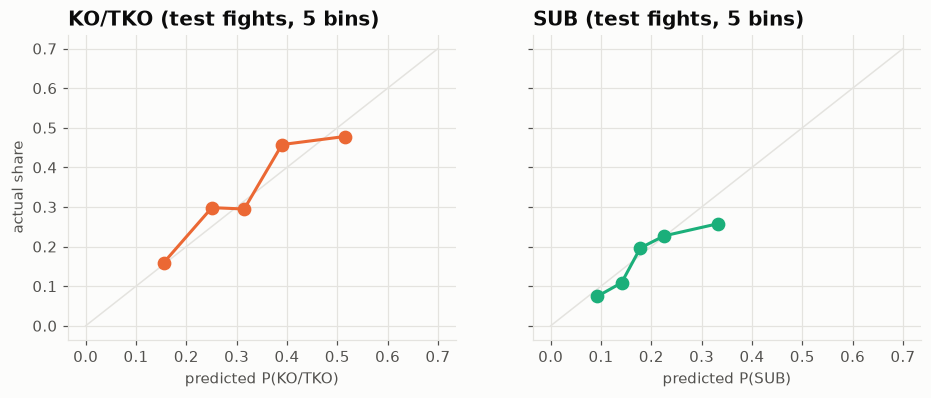

In [11]:
# method calibration on test: predicted vs actual share of each method, by how likely the simulation said a finish was
Hy = T7["hybrid: app P(win) × Markov method"]
pred_ko = Hy[["Red KO/TKO", "Blue KO/TKO"]].sum(axis=1).values
pred_sub = Hy[["Red SUB", "Blue SUB"]].sum(axis=1).values
act = te.method_group.values
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, pred, meth, colr in [(axes[0], pred_ko, "KO/TKO", METHOD_COLORS["KO/TKO"]), (axes[1], pred_sub, "SUB", METHOD_COLORS["SUB"])]:
    bins = pd.qcut(pred, 5, duplicates="drop")
    g = pd.DataFrame({"pred": pred, "act": act == meth}).groupby(bins, observed=True).mean()
    ax.plot([0, 0.7], [0, 0.7], color=GRID, lw=1)
    ax.plot(g.pred, g.act, "o-", color=colr, lw=2, ms=8)
    ax.set_xlabel(f"predicted P({meth})"); ax.set_title(f"{meth} (test fights, 5 bins)")
axes[0].set_ylabel("actual share")
plt.show()

**Reading who-and-how (an honest split decision):**
- **On validation (2021–23), notebook 07's two-step model is best** (1.645 vs 1.659 for the hybrid). By our rule, it stays as the app's method model.
- **On the 2024+ test, the hybrid is best** (1.599 vs 1.614), and it picks the exact outcome most often (34% vs 32%).
  The simulation also gets the method right more often than anything else on test (51%).
- So the simulation's view of finishing *mechanics* (power per strike, chin, submission conversion, time on the mat) is at least as good as the career method mix, and may be better. Two periods disagree on which is ahead, so we don't switch on the strength of the test.
- **Calibration panels:**
  - KO/TKO predictions follow the diagonal well.
  - Submission predictions are too high at the top end: fights the simulation calls most submission-prone end by submission less often than it says.

## 8 · Dream fights
Now the fun part. These use every fight through today, with each fighter's recency-weighted rates as they stand now. Each matchup is simulated 10,000 times.
Five-round fights are title-fight length. The win % is the **raw simulation**: it doesn't know about age or record. That's the job of the app model.

In [12]:
S_now = MK.Simulator(ff, fights.date.max() + pd.Timedelta(days=1), MK.Params(**CHOSEN, **{k: getattr(S24.P, k) for k in CAL}), half_life=HL)
short = lambda n: {"Zhang Weili": "Zhang", "Georges St-Pierre": "St-Pierre"}.get(n, n.split()[-1])
dream = [("Islam Makhachev", "Ilia Topuria", 5), ("Jon Jones", "Tom Aspinall", 5), ("Alexander Volkanovski", "Max Holloway", 5),
         ("Khabib Nurmagomedov", "Islam Makhachev", 5), ("Valentina Shevchenko", "Zhang Weili", 5), ("Georges St-Pierre", "Kamaru Usman", 5)]
rows, sims = [], {}
for a, b, r in dream:
    o = S_now.matchup(a, b, rounds=r, n=10000, seed=7, log=5)
    sims[(a, b)] = o
    rows.append({"matchup": f"{a} vs {b}", **{k.replace("A ", short(a) + " ").replace("B ", short(b) + " "): float(o[k][0]) for k in MK.OUT7},
                 f"P(first named wins)": float(o["p_a"][0]),
                 "finish rate": float(1 - o["A DEC"][0] - o["B DEC"][0]),
                 "strikes landed (first named)": float(o["mean_a_sig"][0]), "strikes landed (second)": float(o["mean_b_sig"][0]),
                 "takedowns (first named)": float(o["mean_a_td"][0]), "takedowns (second)": float(o["mean_b_td"][0])})
summary = pd.DataFrame(rows).set_index("matchup")
display(summary[["P(first named wins)", "finish rate", "strikes landed (first named)", "strikes landed (second)", "takedowns (first named)", "takedowns (second)"]].round(2))

,P(first named wins),finish rate,strikes landed (first named),strikes landed (second),takedowns (first named),takedowns (second)
matchup,,,,,,
Islam Makhachev vs Ilia Topuria,0.59,0.60,51.13,50.49,1.52,0.58
Jon Jones vs Tom Aspinall,0.53,0.85,49.75,41.83,0.82,0.52
Alexander Volkanovski vs Max Holloway,0.55,0.48,95.24,88.41,1.22,0.38
Khabib Nurmagomedov vs Islam Makhachev,0.53,0.52,50.26,43.46,1.79,1.83
Valentina Shevchenko vs Zhang Weili,0.62,0.28,46.09,46.34,3.83,1.16
Georges St-Pierre vs Kamaru Usman,0.69,0.49,69.30,50.45,1.54,1.09


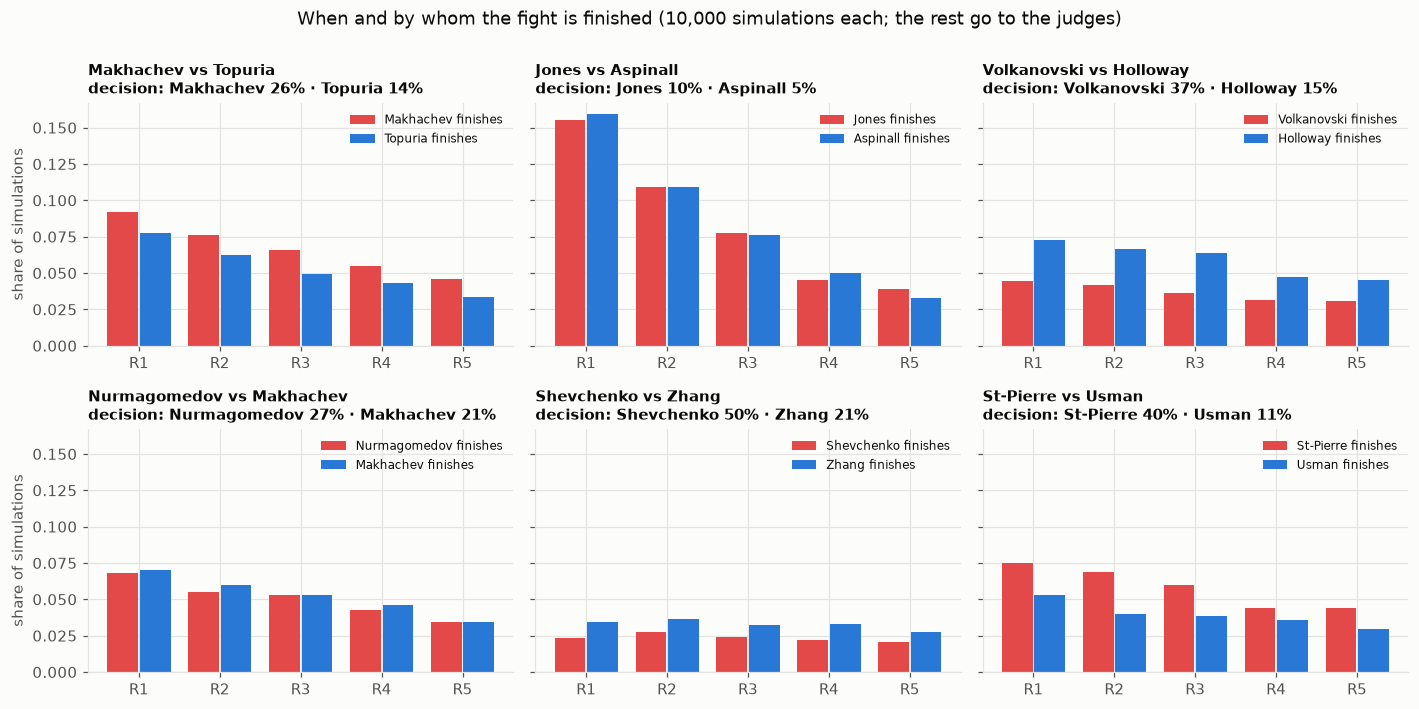

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharey=True)
for ax, (a, b, r) in zip(axes.flat, dream):
    o = sims[(a, b)]
    rr = np.arange(1, r + 1)
    fa, fb = o["a_finish_round"][0], o["b_finish_round"][0]
    ax.bar(rr - 0.2, fa, 0.38, color=RED_CORNER, label=f"{short(a)} finishes")
    ax.bar(rr + 0.2, fb, 0.38, color=BLUE_CORNER, label=f"{short(b)} finishes")
    dec_a, dec_b = float(o["A DEC"][0]), float(o["B DEC"][0])
    ax.set_title(f"{short(a)} vs {short(b)}\ndecision: {short(a)} {dec_a:.0%} · {short(b)} {dec_b:.0%}", fontsize=10)
    ax.set_xticks(rr, [f"R{i}" for i in rr]); ax.legend(frameon=False, fontsize=8)
axes[0, 0].set_ylabel("share of simulations"); axes[1, 0].set_ylabel("share of simulations")
fig.suptitle("When and by whom the fight is finished (10,000 simulations each; the rest go to the judges)", y=1.0)
plt.tight_layout(); plt.show()

## 9 · Inside the Monte Carlo
A Monte Carlo estimate is just an average over many random runs. These charts open up one matchup, Makhachev vs Topuria over 5 rounds, to show what the 10,000 simulations actually look like:
1. **Convergence:** how the win estimate settles as simulations accumulate, and why 10,000 is enough.
2. **The full outcome split** for every dream fight.
3. **Distributions:** fight length, strikes landed, takedowns, across all 10,000 fights.
4. **When and how it ends:** a round × method heatmap.
5. **200 fights at once:** each simulated fight's strike race, which spreads out into very different stories.
6. **One fight's timeline:** position, strikes and key events second by second. It's a static preview of what the website will animate.

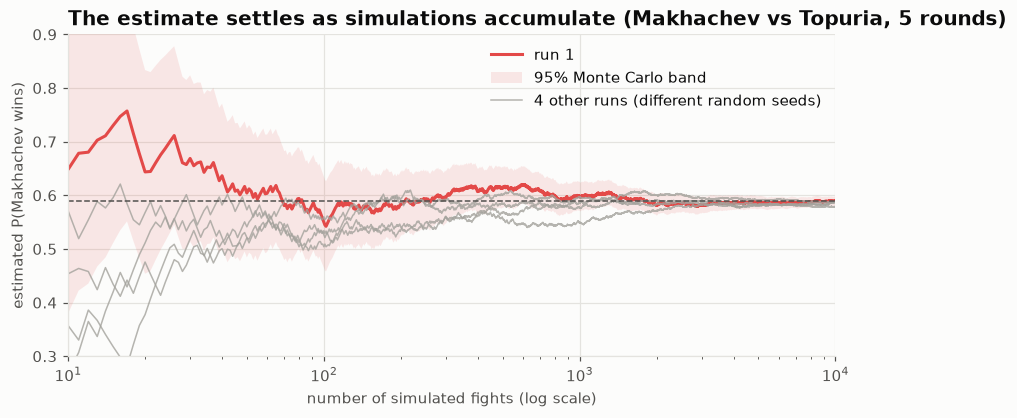

P(Makhachev wins) = 59.0% ± 0.8% (95% Monte Carlo error after 10,000 fights; after 100 it would be ± 8.5%)


In [14]:
A, B = "Islam Makhachev", "Ilia Topuria"
a_, b_ = short(A), short(B)
mc = S_now.matchup(A, B, rounds=5, n=10000, seed=7, log=200, raw=True)
raw = {k: v[0] for k, v in mc["raw"].items()}

# 1. convergence: running estimate of P(Makhachev wins) for 5 independent runs, with the 95% Monte Carlo band of the first
fig, ax = plt.subplots(figsize=(9, 3.8))
n = np.arange(1, 10001)
for s in range(5):
    w = raw["a_wins"] if s == 0 else S_now.matchup(A, B, rounds=5, n=10000, seed=100 + s, raw=True)["raw"]["a_wins"][0]
    run = np.cumsum(w) / n
    ax.plot(n, run, color=RED_CORNER if s == 0 else NEUTRAL, lw=2 if s == 0 else 1, alpha=1 if s == 0 else 0.8,
            label="run 1" if s == 0 else ("4 other runs (different random seeds)" if s == 1 else None))
    if s == 0:
        se = raw["a_wins"].std() / np.sqrt(n)
        ax.fill_between(n, run - 1.96 * se, run + 1.96 * se, color=RED_CORNER, alpha=0.12, lw=0, label="95% Monte Carlo band")
final = raw["a_wins"].mean()
ax.axhline(final, color=INK_2, lw=1, ls="--")
ax.set_xscale("log"); ax.set_xlim(10, 10000); ax.set_ylim(0.3, 0.9)
ax.set_xlabel("number of simulated fights (log scale)"); ax.set_ylabel(f"estimated P({a_} wins)")
ax.set_title(f"The estimate settles as simulations accumulate ({a_} vs {b_}, 5 rounds)"); ax.legend(frameon=False, loc="upper right")
plt.show()
se_final = raw["a_wins"].std() / np.sqrt(10000)
print(f"P({a_} wins) = {final:.1%} ± {1.96 * se_final:.1%} (95% Monte Carlo error after 10,000 fights; after 100 it would be ± {1.96 * raw['a_wins'].std() / 10:.1%})")

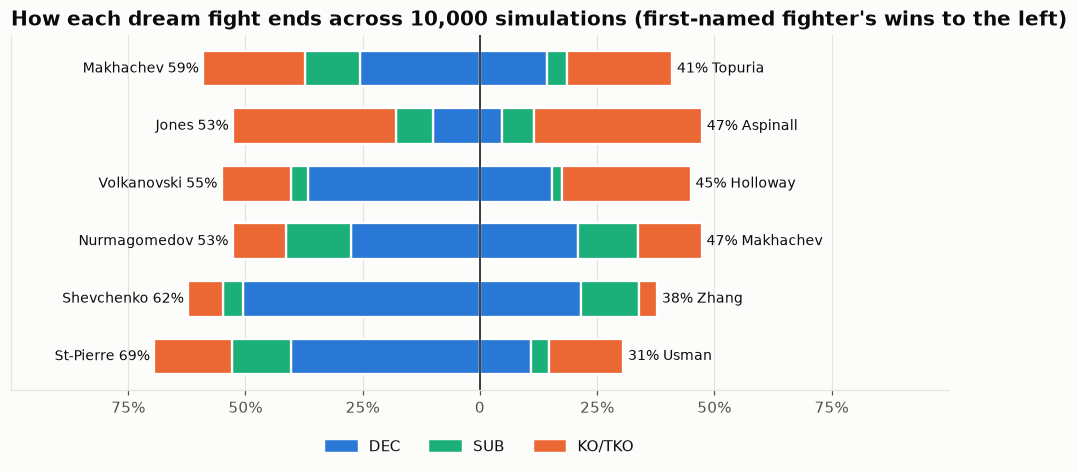

In [15]:
# 2. the full outcome split for every dream fight: first-named fighter's wins to the left, second-named to the right
fig, ax = plt.subplots(figsize=(11, 4.2))
labels = []
for i, (a, b, r) in enumerate(dream):
    o = sims[(a, b)]
    left = 0.0
    for k, meth in [("A DEC", "DEC"), ("A SUB", "SUB"), ("A KO/TKO", "KO/TKO")]:
        v = float(o[k][0]); ax.barh(i, -v, left=-left, color=METHOD_COLORS[meth], height=0.62, edgecolor="white", lw=1.5); left += v
    right = 0.0
    for k, meth in [("B DEC", "DEC"), ("B SUB", "SUB"), ("B KO/TKO", "KO/TKO")]:
        v = float(o[k][0]); ax.barh(i, v, left=right, color=METHOD_COLORS[meth], height=0.62, edgecolor="white", lw=1.5); right += v
    ax.text(-left - 0.01, i, f"{short(a)} {left:.0%}", ha="right", va="center", fontsize=9)
    ax.text(right + 0.01, i, f"{right:.0%} {short(b)}", ha="left", va="center", fontsize=9)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_yticks([]); ax.set_xlim(-1.0, 1.0); ax.invert_yaxis()
ax.set_xticks([-0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75], ["75%", "50%", "25%", "0", "25%", "50%", "75%"])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=METHOD_COLORS[m], label=m) for m in ["DEC", "SUB", "KO/TKO"]], frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.22))
ax.set_title("How each dream fight ends across 10,000 simulations (first-named fighter's wins to the left)")
plt.show()

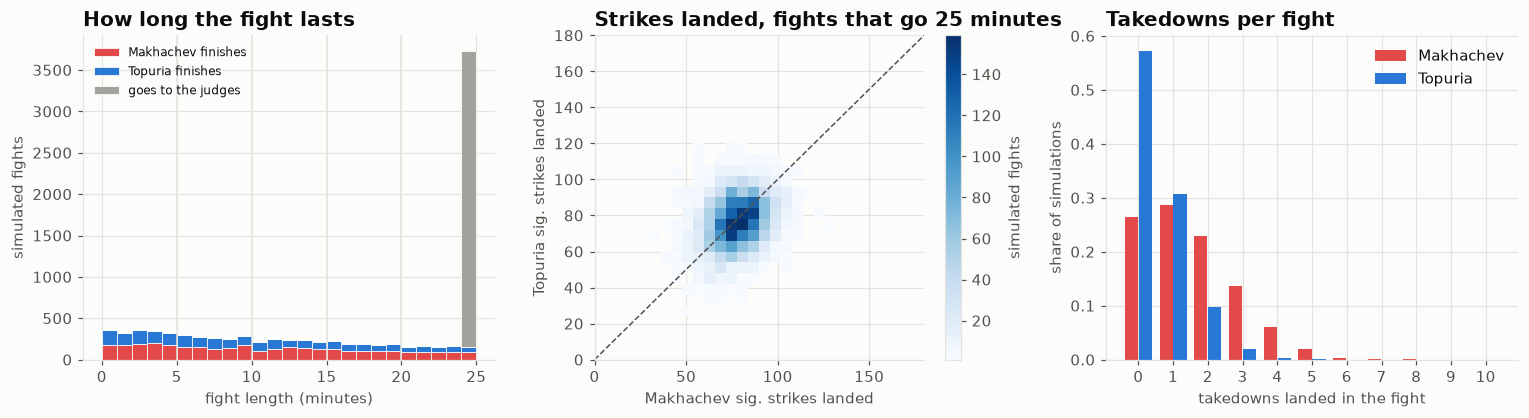

median fight length 18.9 min · 40% go the distance · Makhachev lands 56 strikes (median), Topuria 55 · Makhachev lands at least one takedown in 74% of fights


In [16]:
# 3. distributions across all 10,000 simulations
end, mins = raw["end"], raw["minutes"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
bins = np.arange(0, 25.5, 1)
groups = [(mins[(end == 1) | (end == 2)], RED_CORNER, f"{a_} finishes"), (mins[(end == 3) | (end == 4)], BLUE_CORNER, f"{b_} finishes"),
          (mins[end == 0], NEUTRAL, "goes to the judges")]
ax.hist([g[0] for g in groups], bins=bins, stacked=True, color=[g[1] for g in groups], label=[g[2] for g in groups], edgecolor="white", lw=0.5)
for r in range(1, 5):
    ax.axvline(5 * r, color=GRID, lw=1)
ax.set_xlabel("fight length (minutes)"); ax.set_ylabel("simulated fights"); ax.set_title("How long the fight lasts"); ax.legend(frameon=False, fontsize=8)

ax = axes[1]
full = end == 0
h = ax.hist2d(raw["a_sig"][full], raw["b_sig"][full], bins=[np.arange(0, 181, 6)] * 2, cmap="Blues", cmin=1)
m_ = 180
ax.plot([0, m_], [0, m_], color=INK_2, lw=1, ls="--")
ax.set_xlabel(f"{a_} sig. strikes landed"); ax.set_ylabel(f"{b_} sig. strikes landed")
ax.set_title("Strikes landed, fights that go 25 minutes")
plt.colorbar(h[3], ax=ax, label="simulated fights")

ax = axes[2]
tda, tdb = raw["a_td"].astype(int), raw["b_td"].astype(int)
k = np.arange(0, 11)
ax.bar(k - 0.2, [(tda == i).mean() for i in k], 0.38, color=RED_CORNER, label=a_)
ax.bar(k + 0.2, [(tdb == i).mean() for i in k], 0.38, color=BLUE_CORNER, label=b_)
ax.set_xticks(k); ax.set_xlabel("takedowns landed in the fight"); ax.set_ylabel("share of simulations")
ax.set_title("Takedowns per fight"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"median fight length {np.median(mins):.1f} min · {full.mean():.0%} go the distance · "
      f"{a_} lands {np.median(raw['a_sig']):.0f} strikes (median), {b_} {np.median(raw['b_sig']):.0f} · "
      f"{a_} lands at least one takedown in {(tda > 0).mean():.0%} of fights")

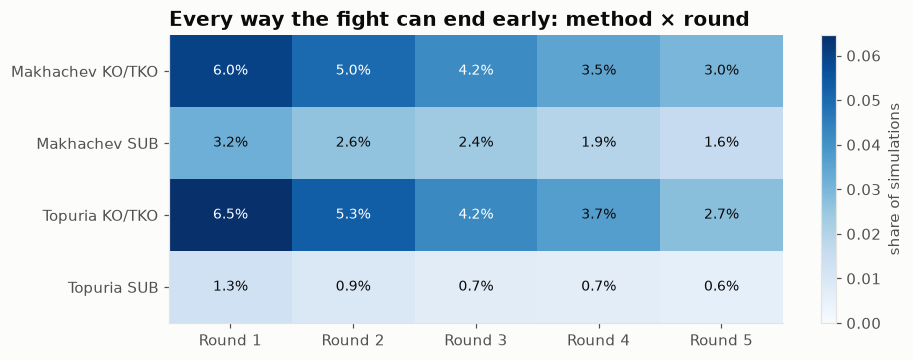

finished early in 60% of simulations · decisions: Makhachev 26%, Topuria 14%


In [17]:
# 4. when and how: round × method heatmap
cells = np.zeros((4, 5))
names_ = [f"{a_} KO/TKO", f"{a_} SUB", f"{b_} KO/TKO", f"{b_} SUB"]
for i, code in enumerate([1, 2, 3, 4]):
    for r in range(5):
        cells[i, r] = ((end == code) & (raw["end_round"] == r + 1)).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(cells, cmap="Blues", aspect="auto", vmin=0)
for i in range(4):
    for r in range(5):
        ax.text(r, i, f"{cells[i, r]:.1%}", ha="center", va="center", fontsize=9, color="white" if cells[i, r] > cells.max() * 0.6 else "#0b0b0b")
ax.set_xticks(range(5), [f"Round {r}" for r in range(1, 6)]); ax.set_yticks(range(4), names_)
ax.grid(False)
dec_a, dec_b = float((full * raw["p_dec_a"]).mean()), float((full * (1 - raw["p_dec_a"])).mean())
ax.set_title("Every way the fight can end early: method × round")
plt.colorbar(im, ax=ax, label="share of simulations")
plt.show()
print(f"finished early in {cells.sum():.0%} of simulations · decisions: {a_} {dec_a:.0%}, {b_} {dec_b:.0%}")

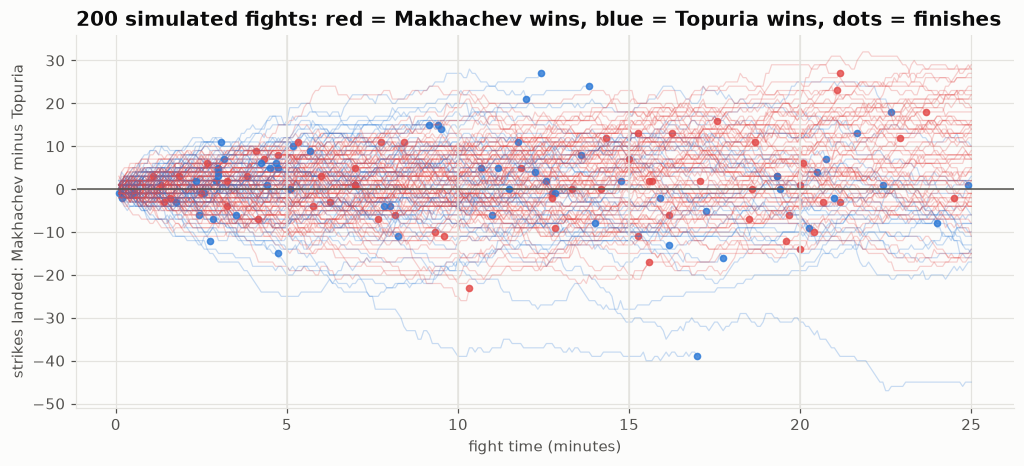

In [18]:
# 5. 200 fights at once: the running strike differential, colored by who ends up winning
fig, ax = plt.subplots(figsize=(11, 4.4))
logs = mc["logs"]
sa = np.array([L["sa"][0] for L in logs], float)      # (steps, 200)
sb = np.array([L["sb"][0] for L in logs], float)
diff = np.cumsum(sa - sb, axis=0)
t_min = (np.arange(len(logs)) + 1) * MK.DT / 60
e200, r200, p200 = mc["log_end"][0], mc["log_end_round"][0], mc["log_p_dec_a"][0]
for j in range(200):
    stop = len(logs) if e200[j] == 0 else int(np.argmax([L["end"][0, j] > 0 for L in logs])) + 1
    a_won = (e200[j] in (1, 2)) or (e200[j] == 0 and p200[j] >= 0.5)
    col = RED_CORNER if a_won else BLUE_CORNER
    ax.plot(t_min[:stop], diff[:stop, j], color=col, alpha=0.25, lw=0.8)
    if e200[j]:
        ax.plot(t_min[stop - 1], diff[stop - 1, j], "o", color=col, ms=4, alpha=0.8)
for r in range(1, 5):
    ax.axvline(5 * r, color=GRID, lw=1)
ax.axhline(0, color=INK_2, lw=1)
ax.set_xlabel("fight time (minutes)"); ax.set_ylabel(f"strikes landed: {a_} minus {b_}")
ax.set_title(f"200 simulated fights: red = {a_} wins, blue = {b_} wins, dots = finishes")
plt.show()

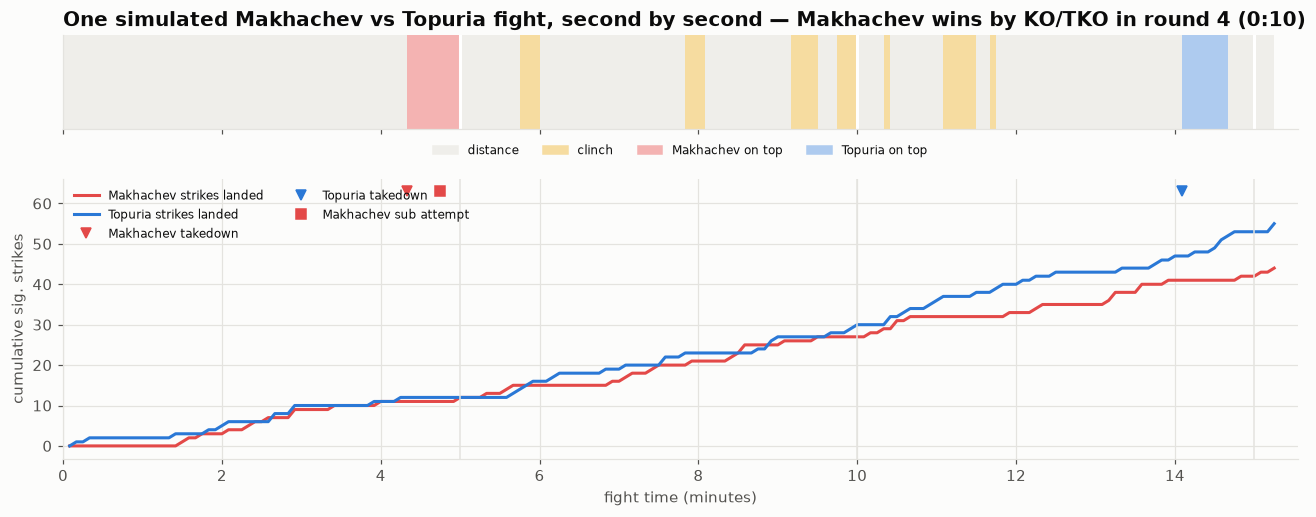

In [19]:
# 6. one fight's timeline: position ribbon + cumulative strikes + key events
j = next((j for j in range(200) if e200[j] == 0 or r200[j] >= 3), 0)     # a fight that lasts long enough to be interesting
pos = np.array([L["pos"][0, j] for L in logs])
stop = len(logs) if e200[j] == 0 else int(np.argmax([L["end"][0, j] > 0 for L in logs])) + 1
pos_colors = {0: "#efeeea", 1: "#f6dca0", 2: "#f4b3b2", 3: "#aecbef"}
pos_names = {0: "distance", 1: "clinch", 2: f"{a_} on top", 3: f"{b_} on top"}
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True, gridspec_kw={"height_ratios": [1, 3]})
for s in range(stop):
    ax0.axvspan(s * MK.DT / 60, (s + 1) * MK.DT / 60, color=pos_colors[int(pos[s])], lw=0)
ev, strikes, result = MK.play_by_play(mc, (a_, b_), 0, j)
ax0.set_yticks([]); ax0.set_title(f"One simulated {a_} vs {b_} fight, second by second — {result}")
ax0.legend(handles=[Patch(color=pos_colors[k], label=v) for k, v in pos_names.items()], ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.05), fontsize=8)
ax1.plot(t_min[:stop], np.cumsum(sa[:stop, j]), color=RED_CORNER, lw=2, label=f"{a_} strikes landed")
ax1.plot(t_min[:stop], np.cumsum(sb[:stop, j]), color=BLUE_CORNER, lw=2, label=f"{b_} strikes landed")
marks = [("tda", "v", RED_CORNER, f"{a_} takedown"), ("tdb", "v", BLUE_CORNER, f"{b_} takedown"),
         ("kda", "*", RED_CORNER, f"{a_} knockdown"), ("kdb", "*", BLUE_CORNER, f"{b_} knockdown"),
         ("suba", "s", RED_CORNER, f"{a_} sub attempt"), ("subb", "s", BLUE_CORNER, f"{b_} sub attempt")]
top = max(np.cumsum(sa[:stop, j]).max(), np.cumsum(sb[:stop, j]).max()) + 8
for key, mk, col, lab in marks:
    steps = [s for s in range(stop) if logs[s][key][0, j]]
    if steps:
        ax1.plot(t_min[steps], np.full(len(steps), top), mk, color=col, ms=9 if mk == "*" else 6, label=lab, ls="none")
for r in range(1, 5):
    if 5 * r < t_min[stop - 1]:
        ax1.axvline(5 * r, color=GRID, lw=1); ax0.axvline(5 * r, color="white", lw=2)
ax1.set_xlim(0, t_min[stop - 1] + 0.3)
ax1.set_xlabel("fight time (minutes)"); ax1.set_ylabel("cumulative sig. strikes")
ax1.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

**Reading the Monte Carlo charts:**
- **Convergence:** after 100 fights the estimate still wobbles by several points. After 10,000 the Monte Carlo error is about one point, much smaller than the model's real uncertainty.
  More simulations make the *simulation* precise, not the *model*.
- **Distributions:** the same two fighters produce very different fights. There are early finishes, grinding decisions, and fights where the underdog lands more.
  A single "predicted stat line" hides all of that. The averages earlier in the notebook are the centers of these distributions.
- **The 200-fight spaghetti:** most simulations drift in one direction, but plenty cross zero, and finishes (dots) can come from either side at any time. That spread is why even a 60% favorite loses 4 fights in 10.
- **The timeline** is one draw from the chain. The website version will animate it step by step.

### Watch one simulated fight
One of the 10,000 Makhachev vs Topuria simulations, play by play. Each run is different; that randomness is the point.
This event log is what the website will animate later.

In [20]:
o = sims[("Islam Makhachev", "Ilia Topuria")]
for j in range(5):
    ev, strikes, result = MK.play_by_play(o, ("Makhachev", "Topuria"), 0, j)
    print(f"simulation {j + 1}: {result}")
ev, strikes, result = MK.play_by_play(o, ("Makhachev", "Topuria"), 0, 0)
print("\nsimulation 1 in detail —", result)
display(ev)
display(strikes.rename(columns=lambda c: f"{c} sig. strikes landed"))

simulation 1: Makhachev wins by KO/TKO in round 4 (0:10)
simulation 2: Topuria wins by KO/TKO in round 2 (2:55)
simulation 3: Goes the distance: judges favor Makhachev (63% likely)
simulation 4: Topuria wins by submission in round 1 (2:30)
simulation 5: Goes the distance: judges favor Makhachev (92% likely)

simulation 1 in detail — Makhachev wins by KO/TKO in round 4 (0:10)


,round,clock,event
0,1,4:15,Makhachev lands a takedown
1,1,4:40,Makhachev attempts a submission
2,2,0:45,Clinch against the fence
3,2,1:00,They break apart
4,2,2:50,Clinch against the fence
5,2,3:05,They break apart
6,2,4:10,Clinch against the fence
7,2,4:30,They break apart
8,2,4:45,Clinch against the fence
9,3,0:20,Clinch against the fence


,Makhachev sig. strikes landed,Topuria sig. strikes landed
round,,
1,12,12
2,15,18
3,15,23
4,2,2


## Takeaways
1. **The published model's idea works with our data.** Box-score totals are enough to rebuild a fight as positions, strikes, takedowns and submission attempts.
   Calibrated on four league numbers, the simulated UFC reproduces strike rates, takedown rates and fight lengths it was never tuned on.
2. **Simulating beats regressing on the same inputs.** Given only how fighters fight, the simulation outperforms a logistic regression on those same rates. Positions, finishes and judges are real structure.
3. **It doesn't beat the app model for *who wins* on its own.** The app model also knows age, record, opposition quality and UFC matchmaking.
4. **Adding it to the app model is a close call.** Validation said no, by a hair (0.6420 vs 0.6415). The 2024+ test says yes, clearly: 65.8% vs 63.8% accuracy, and a log-loss gain whose 95% interval excludes zero.
   We stick to the rule and don't switch the live model on a test result. That's how test sets stay honest. The blend is the first candidate to re-check when a fresh season of fights arrives.
5. **For *how*, it's level with the career method mix.** Validation favors notebook 07's two-step model; test favors the hybrid (app model's winner × the simulation's method).
6. **It plays out fights that never happened.** It gives round-by-round finish odds, expected stat lines, and a full event log for any matchup. That's the foundation for the website's simulator, the next step.

**Limitations worth knowing:**
- No fatigue, cuts, or round-to-round adjustments; real finishes cluster earlier than the simulation's.
- Position times are estimated from control time.
- Rates don't adjust for the quality of past opponents.
- Debutants are division-average.